# Loading Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 6)
sns.set_style('darkgrid')

In [2]:
districts = pd.read_csv('districts.csv')
weather = pd.read_csv('weather.csv')
traffic = pd.read_csv('traffic.csv')
transport = pd.read_csv('public_transport.csv')
power = pd.read_csv('power_grid.csv')
air = pd.read_csv('air_quality.csv')
events = pd.read_csv('city_events.csv')
emergency = pd.read_csv('emergency_events.csv')

# Preparing merge keys

In [3]:
hourly_tables = [weather, traffic, transport, power, air]
for table in hourly_tables:
    table['timestamp'] = pd.to_datetime(table['timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

events['start_timestamp'] = pd.to_datetime(events['start_timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
events['end_timestamp'] = pd.to_datetime(events['end_timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

emergency['timestamp'] = pd.to_datetime(emergency['timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
emergency_hourly = emergency.copy()
emergency_hourly['timestamp'] = emergency_hourly['timestamp'].dt.floor('h')

weather = weather.drop_duplicates(['district_id', 'timestamp'])
traffic = traffic.drop_duplicates(['district_id', 'timestamp'])
transport = transport.drop_duplicates(['district_id', 'timestamp'])
power = power.drop_duplicates(['district_id', 'timestamp'])
air = air.drop_duplicates(['district_id', 'timestamp'])

In [4]:
def find_outliers_iqr(df, column):
    Q1, Q3 = df[column].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    return df[(df[column] < lower) | (df[column] > upper)]

def event_window_data(events_data, operational_data, value_columns):

    data = operational_data.merge(
        events_data[['event_id', 'district_id', 'start_timestamp', 'end_timestamp', 'event_type', 'event_impact_level']],
        on='district_id'
    )

    data = data[ (data['timestamp'] >= data['start_timestamp']) & (data['timestamp'] <= data['end_timestamp']) ]

    columns = ['timestamp', 'district_id'] + value_columns + ['event_id', 'event_type', 'event_impact_level']
    return data[columns]

# Cross Table Outlier Validation

## Weather power outliers

In [5]:
weather_power = weather.merge(power, on=['district_id', 'timestamp'], suffixes=('_weather', '_power'))

demand_over_capacity = weather_power[weather_power['electricity_demand_mwh'] > weather_power['grid_capacity_mwh']]

print('Demand over capacity observations:', len(demand_over_capacity))
demand_over_capacity.groupby('weather_condition').size().sort_values(ascending=False)
#The demand over capacity problem is not because of heatwaves

Demand over capacity observations: 3144


weather_condition
Clear            1067
Partly Cloudy     970
Heatwave          702
Rain              254
Storm              81
Cloudy             40
Heavy Rain         30
dtype: int64

## Weather air-quality outliers

In [6]:
weather_air = weather.merge(air, on=['district_id', 'timestamp'], suffixes=('_weather', '_air'))

aqi_outliers = find_outliers_iqr(weather_air, 'synthetic_aqi')
aqi_outliers.groupby(['weather_condition', 'air_quality_category']).size().sort_values(ascending=False)
#Most unhealthy air quality is in clear conditions and that's normal because most of conditions are clear

weather_condition  air_quality_category          
Clear              Unhealthy for Sensitive Groups    7626
Partly Cloudy      Unhealthy for Sensitive Groups    7228
Clear              Unhealthy                         2793
Partly Cloudy      Unhealthy                         2742
Clear              Very Unhealthy                    1130
Partly Cloudy      Very Unhealthy                    1115
Heatwave           Unhealthy for Sensitive Groups     424
Cloudy             Unhealthy for Sensitive Groups     364
Rain               Unhealthy for Sensitive Groups     191
Heatwave           Unhealthy                          148
Cloudy             Unhealthy                          112
Heatwave           Very Unhealthy                      51
Cloudy             Very Unhealthy                      45
Heavy Rain         Unhealthy for Sensitive Groups      30
Rain               Unhealthy                            8
dtype: int64

## Event-window outliers

In [7]:
event_traffic = event_window_data(events, traffic, ['traffic_volume', 'congestion_index', 'accident_count'])
event_transport = event_window_data(events, transport, ['passenger_count', 'average_delay_minutes', 'vehicle_occupancy_percent'])
event_power = event_window_data(events, power, ['electricity_demand_mwh', 'grid_capacity_mwh'])

event_congestion_outliers = find_outliers_iqr(event_traffic, 'congestion_index')
event_passenger_outliers = find_outliers_iqr(event_transport, 'passenger_count')
event_overload = event_power[event_power['electricity_demand_mwh'] > event_power['grid_capacity_mwh']]

print('Event period congestion outliers by impact level:')
print(event_congestion_outliers['event_impact_level'].value_counts())
print('='*25)
print('Event period passenger outliers by impact level:')
print(event_passenger_outliers['event_impact_level'].value_counts())
print('='*25)
print('Event period power overloads by impact level:')
print(event_overload['event_impact_level'].value_counts())
#These results are because High impact evenets are much more than other events

Event period congestion outliers by impact level:
Series([], Name: count, dtype: int64)
Event period passenger outliers by impact level:
event_impact_level
High       81
Medium     30
Extreme    28
Low        23
Name: count, dtype: int64
Event period power overloads by impact level:
event_impact_level
High       318
Medium     134
Extreme    105
Low         78
Name: count, dtype: int64


# Important Cross-Table KPIs

## Weather impact on traffic congestion, speed, and accidents

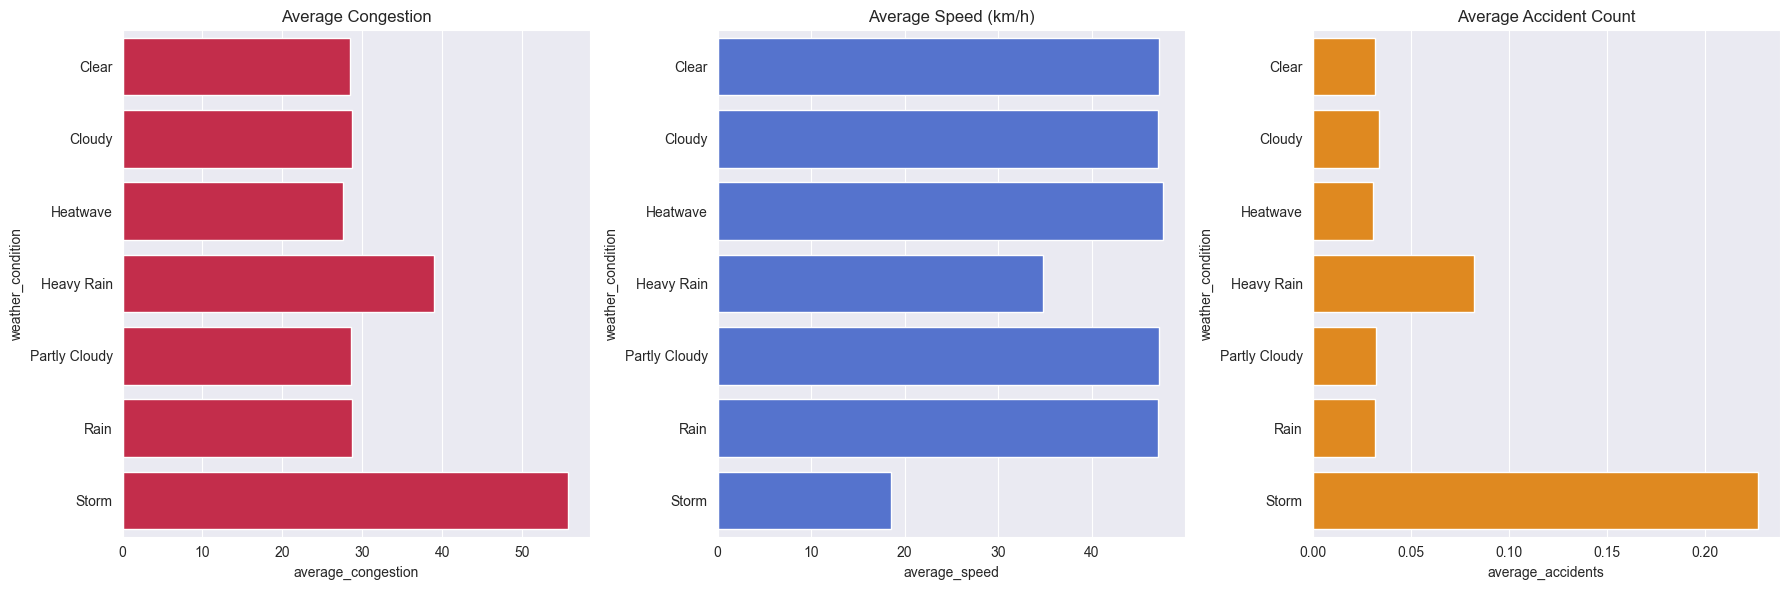

In [8]:
weather_traffic = weather.merge(traffic, on=['district_id', 'timestamp'], suffixes=('_weather', '_traffic'))
weather_traffic_kpi = weather_traffic.groupby('weather_condition').agg(
    average_congestion=('congestion_index', 'mean'),
    average_speed=('average_speed_kmh', 'mean'),
    average_accidents=('accident_count', 'mean')
).reset_index()

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
sns.barplot(weather_traffic_kpi, x='average_congestion', y='weather_condition', color='crimson', ax=ax[0])
ax[0].set_title('Average Congestion')
sns.barplot(weather_traffic_kpi, x='average_speed', y='weather_condition', color='royalblue', ax=ax[1])
ax[1].set_title('Average Speed (km/h)')
sns.barplot(weather_traffic_kpi, x='average_accidents', y='weather_condition', color='darkorange', ax=ax[2])
ax[2].set_title('Average Accident Count')
plt.tight_layout()
plt.show()

## Weather impact on electricity demand and outages

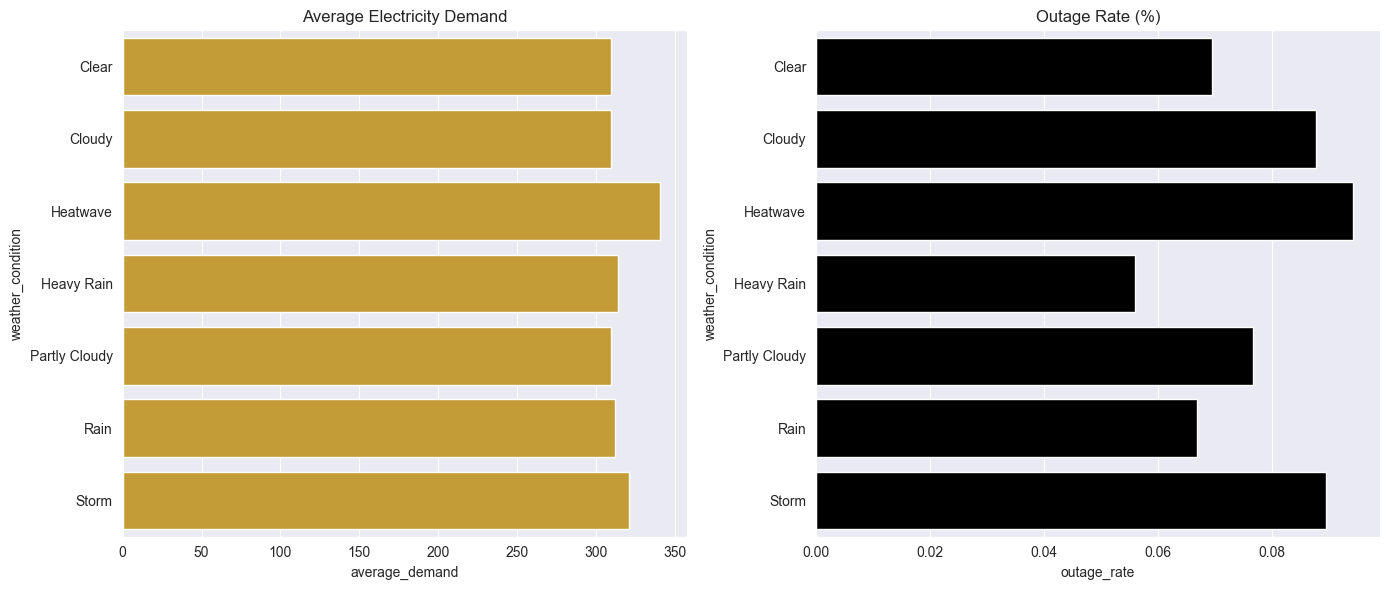

In [9]:
weather_power_kpi = weather_power.groupby('weather_condition').agg(
    average_demand=('electricity_demand_mwh', 'mean'),
    outage_rate=('outage_flag', lambda x: x.mean() * 100)
).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(weather_power_kpi, x='average_demand', y='weather_condition', color='goldenrod', ax=ax[0])
ax[0].set_title('Average Electricity Demand')
sns.barplot(weather_power_kpi, x='outage_rate', y='weather_condition', color='black', ax=ax[1])
ax[1].set_title('Outage Rate (%)')
plt.tight_layout()
plt.show()

## Weather impact on pollution

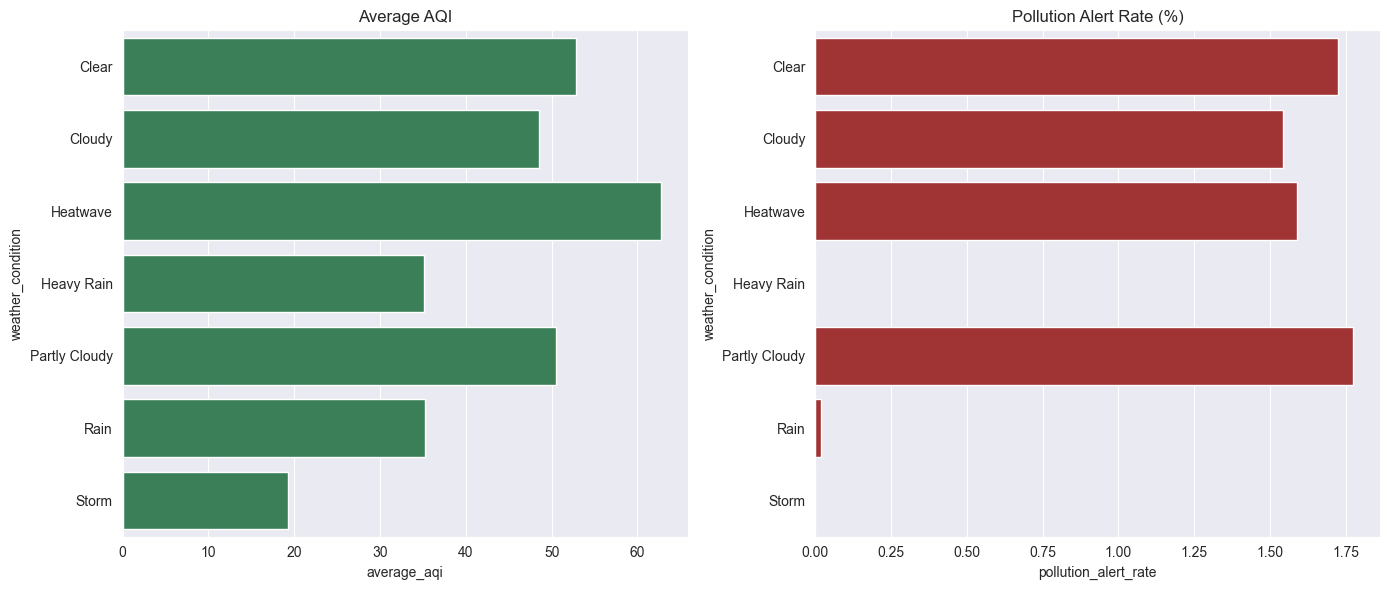

In [10]:
weather_air_kpi = weather_air.groupby('weather_condition').agg(
    average_aqi=('synthetic_aqi', 'mean'),
    pollution_alert_rate=('pollution_alert_flag', lambda x: x.mean() * 100)
).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(weather_air_kpi, x='average_aqi', y='weather_condition', color='seagreen', ax=ax[0])
ax[0].set_title('Average AQI')
sns.barplot(weather_air_kpi, x='pollution_alert_rate', y='weather_condition', color='firebrick', ax=ax[1])
ax[1].set_title('Pollution Alert Rate (%)')
plt.tight_layout()
plt.show()

## Events' impact on traffic and congestion

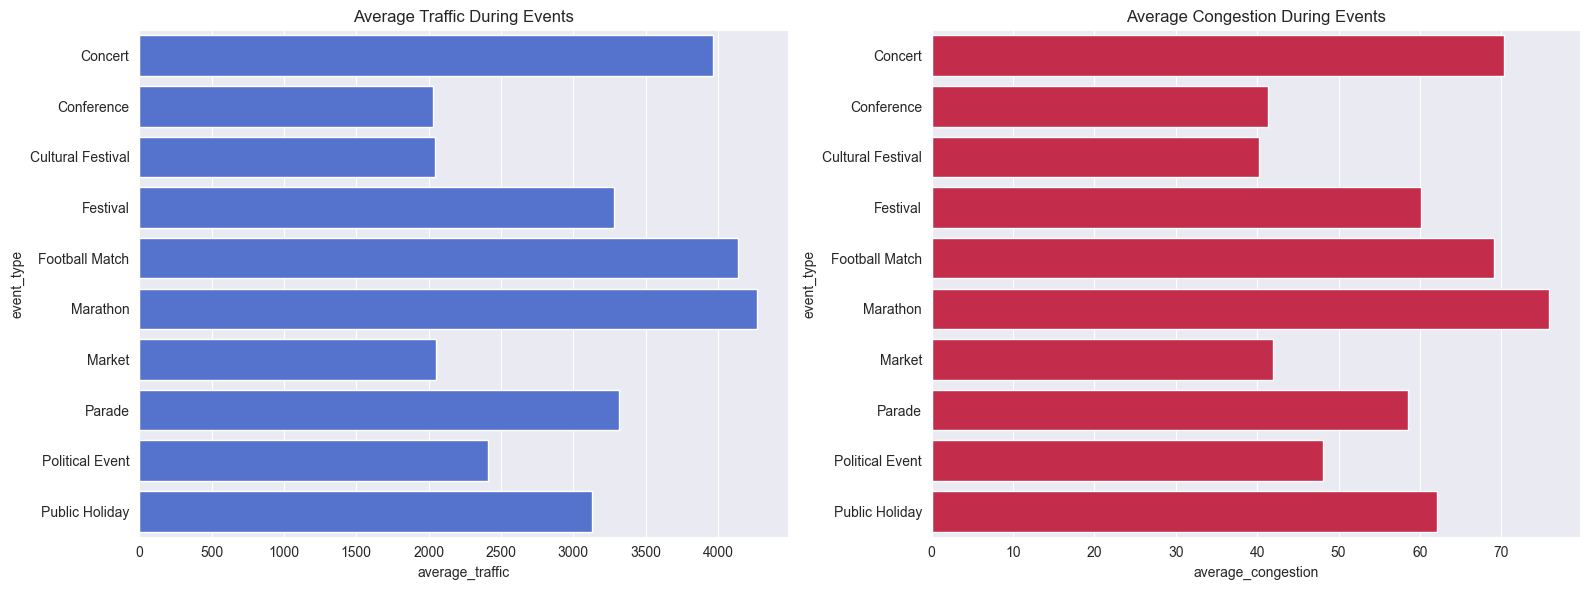

In [11]:
event_traffic_kpi = event_traffic.groupby('event_type').agg(
    average_traffic=('traffic_volume', 'mean'),
    average_congestion=('congestion_index', 'mean')
).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(event_traffic_kpi, x='average_traffic', y='event_type', color='royalblue', ax=ax[0])
ax[0].set_title('Average Traffic During Events')
sns.barplot(event_traffic_kpi, x='average_congestion', y='event_type', color='crimson', ax=ax[1])
ax[1].set_title('Average Congestion During Events')
plt.tight_layout()
plt.show()

## Events' impact on public transport demand

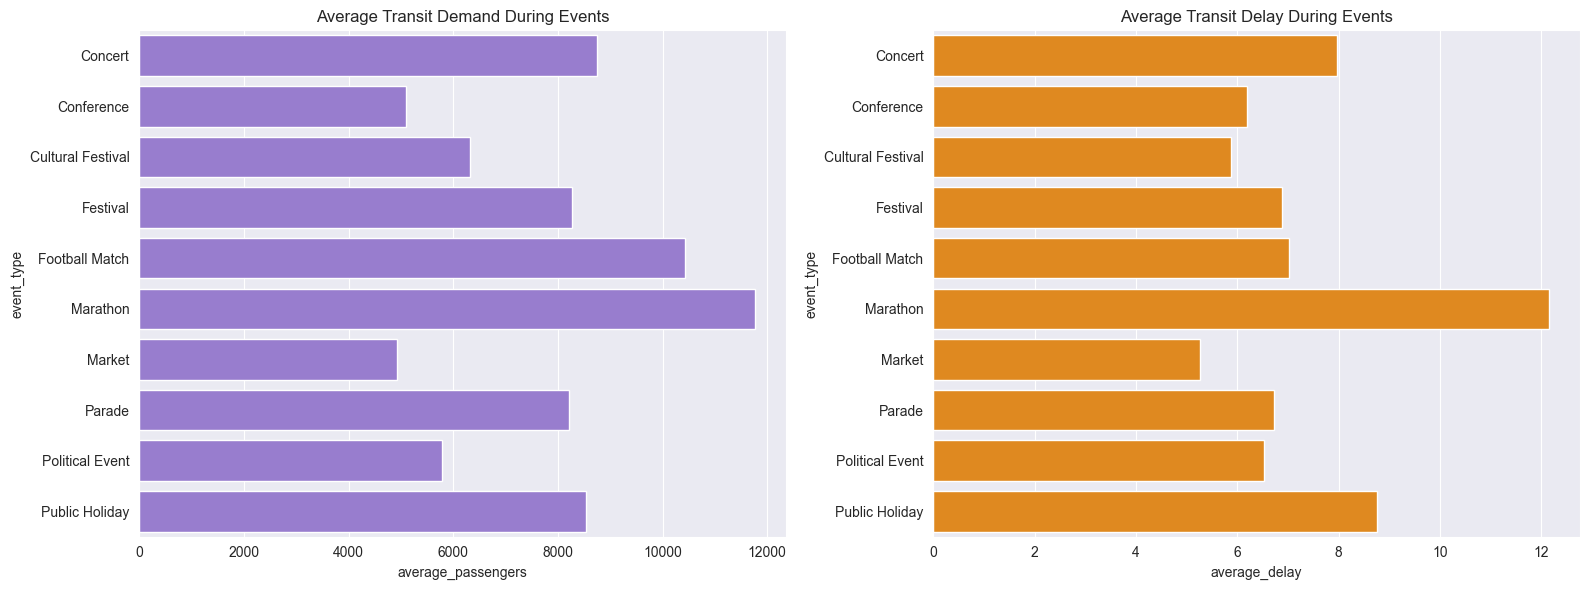

In [12]:
event_transport_kpi = event_transport.groupby('event_type').agg(
    average_passengers=('passenger_count', 'mean'),
    average_delay=('average_delay_minutes', 'mean')
).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(event_transport_kpi, x='average_passengers', y='event_type', color='mediumpurple', ax=ax[0])
ax[0].set_title('Average Transit Demand During Events')
sns.barplot(event_transport_kpi, x='average_delay', y='event_type', color='darkorange', ax=ax[1])
ax[1].set_title('Average Transit Delay During Events')
plt.tight_layout()
plt.show()

## Events' impact on electricity demand

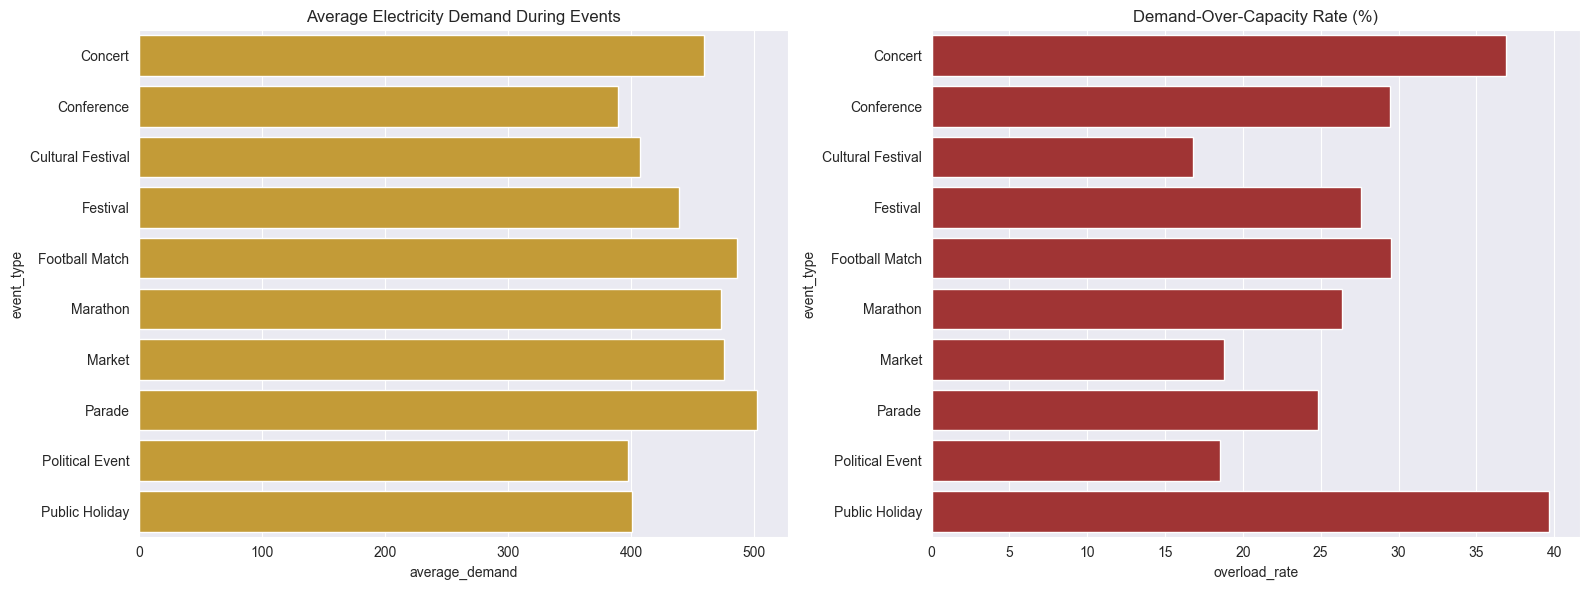

In [13]:
event_power_kpi = event_power.groupby('event_type').agg(
    average_demand=('electricity_demand_mwh', 'mean'),
    overload_rate=('electricity_demand_mwh', lambda x: 0)
).reset_index()

event_power_kpi['overload_rate'] = event_power.groupby('event_type').apply(
    lambda x: (x['electricity_demand_mwh'] > x['grid_capacity_mwh']).mean() * 100
).values

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(event_power_kpi, x='average_demand', y='event_type', color='goldenrod', ax=ax[0])
ax[0].set_title('Average Electricity Demand During Events')
sns.barplot(event_power_kpi, x='overload_rate', y='event_type', color='firebrick', ax=ax[1])
ax[1].set_title('Demand-Over-Capacity Rate (%)')
plt.tight_layout()
plt.show()

## Traffic related emergencies and traffic conditions

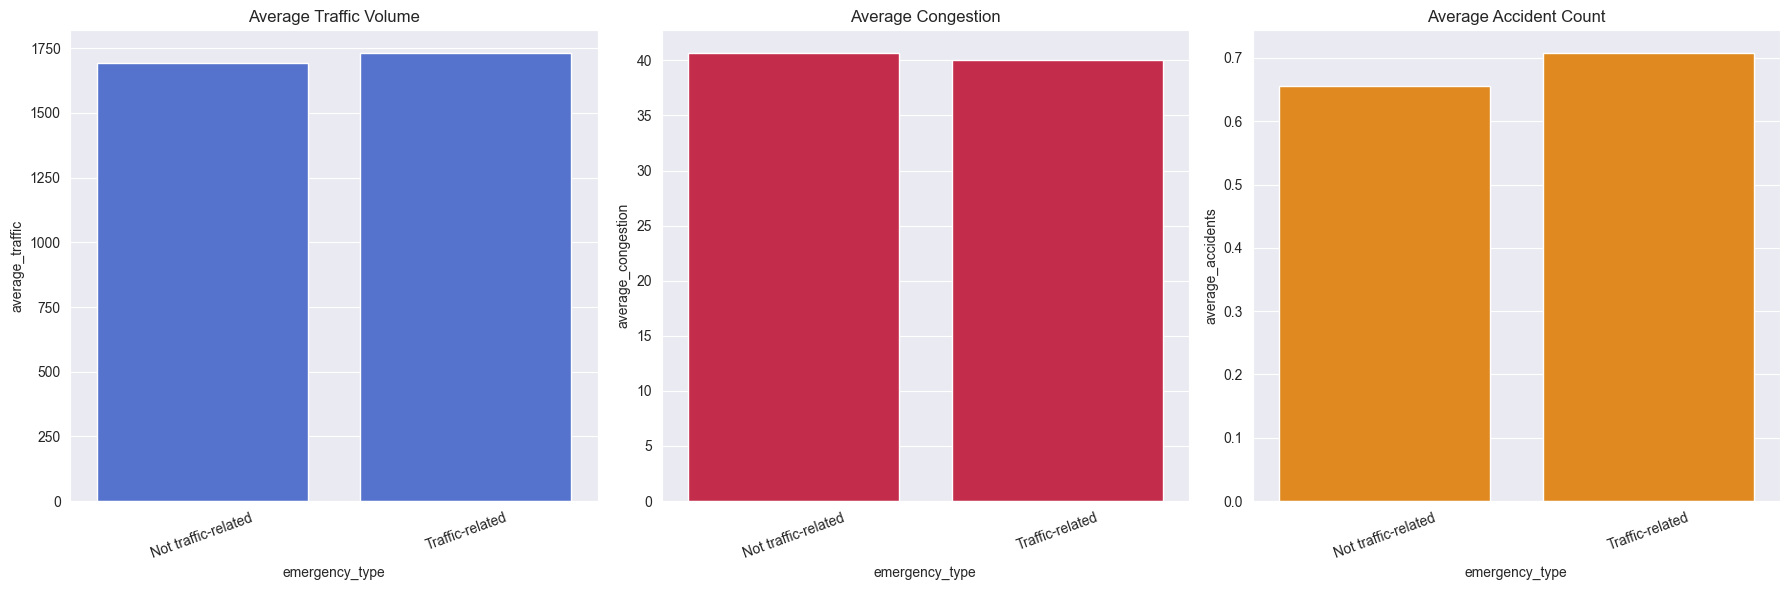

In [14]:
emergency_traffic = emergency_hourly.merge(traffic, on=['district_id', 'timestamp'])
traffic_emergency_kpi = emergency_traffic.groupby('traffic_related_flag').agg(
    average_traffic=('traffic_volume', 'mean'),
    average_congestion=('congestion_index', 'mean'),
    average_accidents=('accident_count', 'mean')
).reset_index()
traffic_emergency_kpi['emergency_type'] = traffic_emergency_kpi['traffic_related_flag'].map({0: 'Not traffic-related', 1: 'Traffic-related'})

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
sns.barplot(traffic_emergency_kpi, x='emergency_type', y='average_traffic', color='royalblue', ax=ax[0])
ax[0].set_title('Average Traffic Volume')
sns.barplot(traffic_emergency_kpi, x='emergency_type', y='average_congestion', color='crimson', ax=ax[1])
ax[1].set_title('Average Congestion')
sns.barplot(traffic_emergency_kpi, x='emergency_type', y='average_accidents', color='darkorange', ax=ax[2])
ax[2].set_title('Average Accident Count')

for axis in ax:
    axis.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

## Weather related emergencies and weather conditions

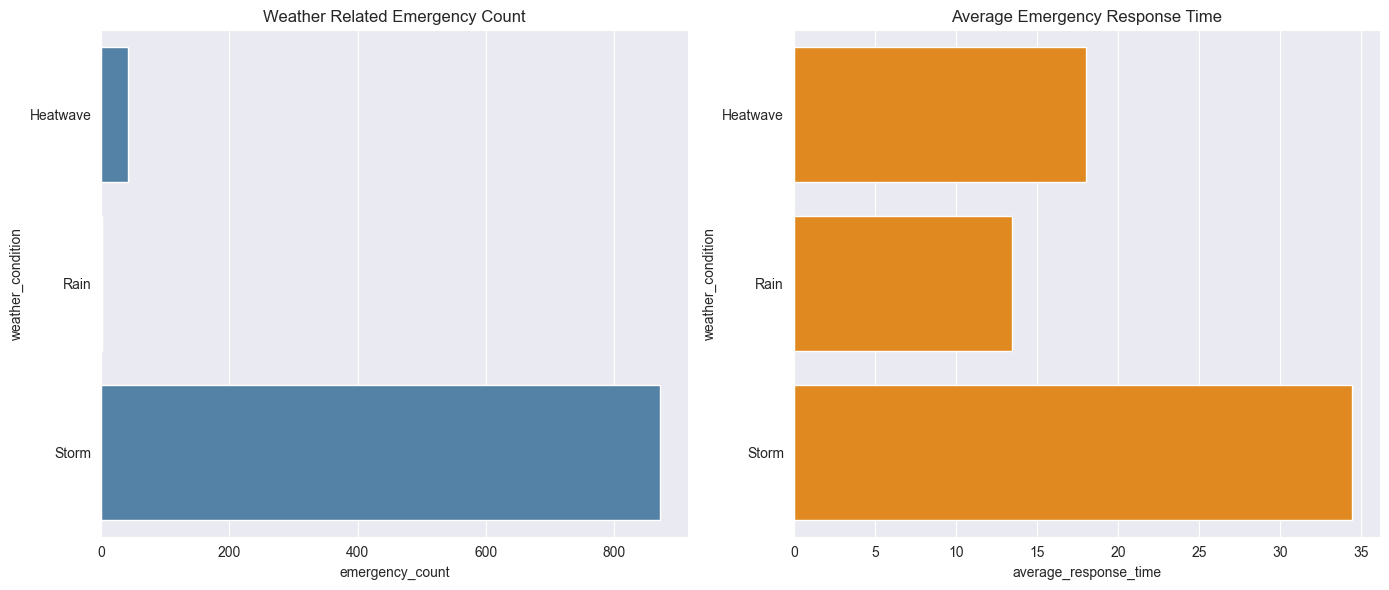

In [15]:
emergency_weather = emergency_hourly.merge(weather, on=['district_id', 'timestamp'])
weather_emergency_kpi = emergency_weather[emergency_weather['weather_related_flag'] == 1].groupby('weather_condition').agg(
    emergency_count=('event_id', 'count'),
    average_response_time=('response_time_minutes', 'mean')
).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(weather_emergency_kpi, x='emergency_count', y='weather_condition', color='steelblue', ax=ax[0])
ax[0].set_title('Weather Related Emergency Count')
sns.barplot(weather_emergency_kpi, x='average_response_time', y='weather_condition', color='darkorange', ax=ax[1])
ax[1].set_title('Average Emergency Response Time')
plt.tight_layout()
plt.show()

## Emergency response time and congestion

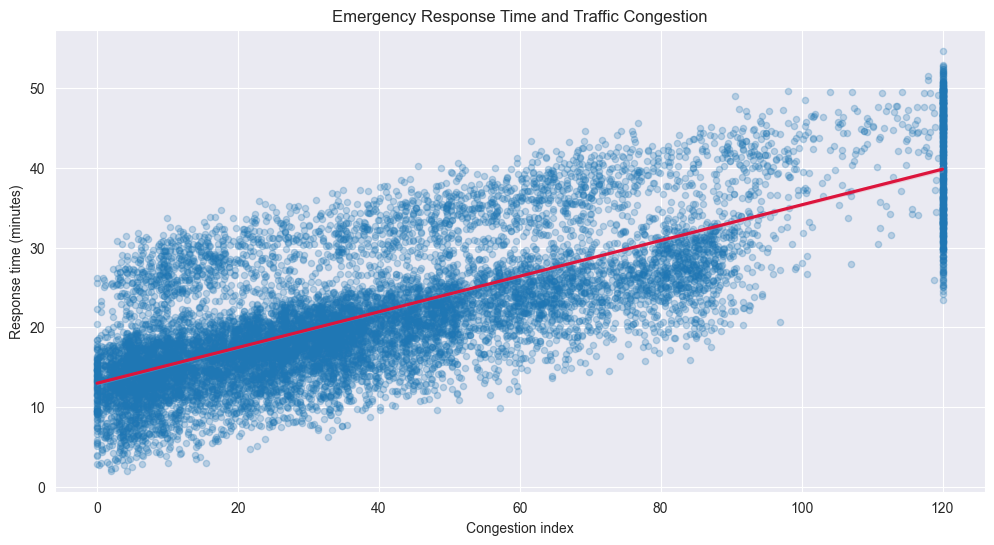

In [16]:
sns.regplot(
    emergency_traffic.dropna(subset=['congestion_index', 'response_time_minutes']),
    x='congestion_index', y='response_time_minutes',
    scatter_kws={'alpha': 0.25, 's': 20}, line_kws={'color': 'crimson'}
)
plt.title('Emergency Response Time and Traffic Congestion')
plt.xlabel('Congestion index')
plt.ylabel('Response time (minutes)')
plt.show()

## District risk profile

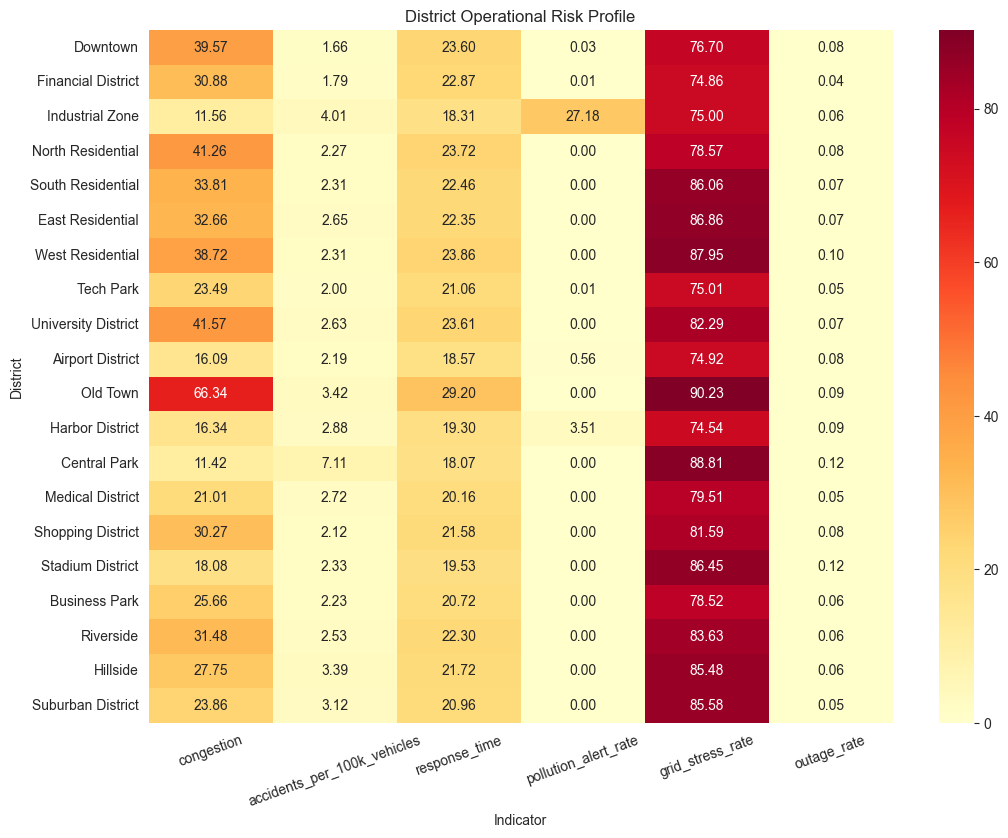

In [17]:
traffic_profile = traffic.groupby('district_id').agg(
    congestion=('congestion_index', 'mean'),
    accidents=('accident_count', 'sum'),
    traffic_volume=('traffic_volume', 'sum')
).reset_index()
traffic_profile['accidents_per_100k_vehicles'] = traffic_profile['accidents'] / traffic_profile['traffic_volume'] * 100000

emergency_profile = emergency.groupby('district_id').agg(
    emergency_count=('event_id', 'count'),
    response_time=('response_time_minutes', 'mean')
).reset_index()

air_profile = air.groupby('district_id').agg(
    pollution_alert_rate=('pollution_alert_flag', lambda x: x.mean() * 100)
).reset_index()

power_profile = power.groupby('district_id').agg(
    grid_stress_rate=('grid_stress_index', lambda x: (x > 0).mean() * 100),
    outage_rate=('outage_flag', lambda x: x.mean() * 100)
).reset_index()

risk_profile = districts.merge(traffic_profile, on='district_id').merge(emergency_profile, on='district_id').merge(air_profile, on='district_id').merge(power_profile, on='district_id')
risk_columns = ['congestion', 'accidents_per_100k_vehicles', 'response_time', 'pollution_alert_rate', 'grid_stress_rate', 'outage_rate']

plt.figure(figsize=(12, 9))
sns.heatmap(risk_profile.set_index('district_name')[risk_columns], cmap='YlOrRd', annot=True, fmt='.2f')
plt.title('District Operational Risk Profile')
plt.xlabel('Indicator')
plt.ylabel('District')
plt.xticks(rotation=20)
plt.show()

## Population adjusted accident, emergency, and pollution rates

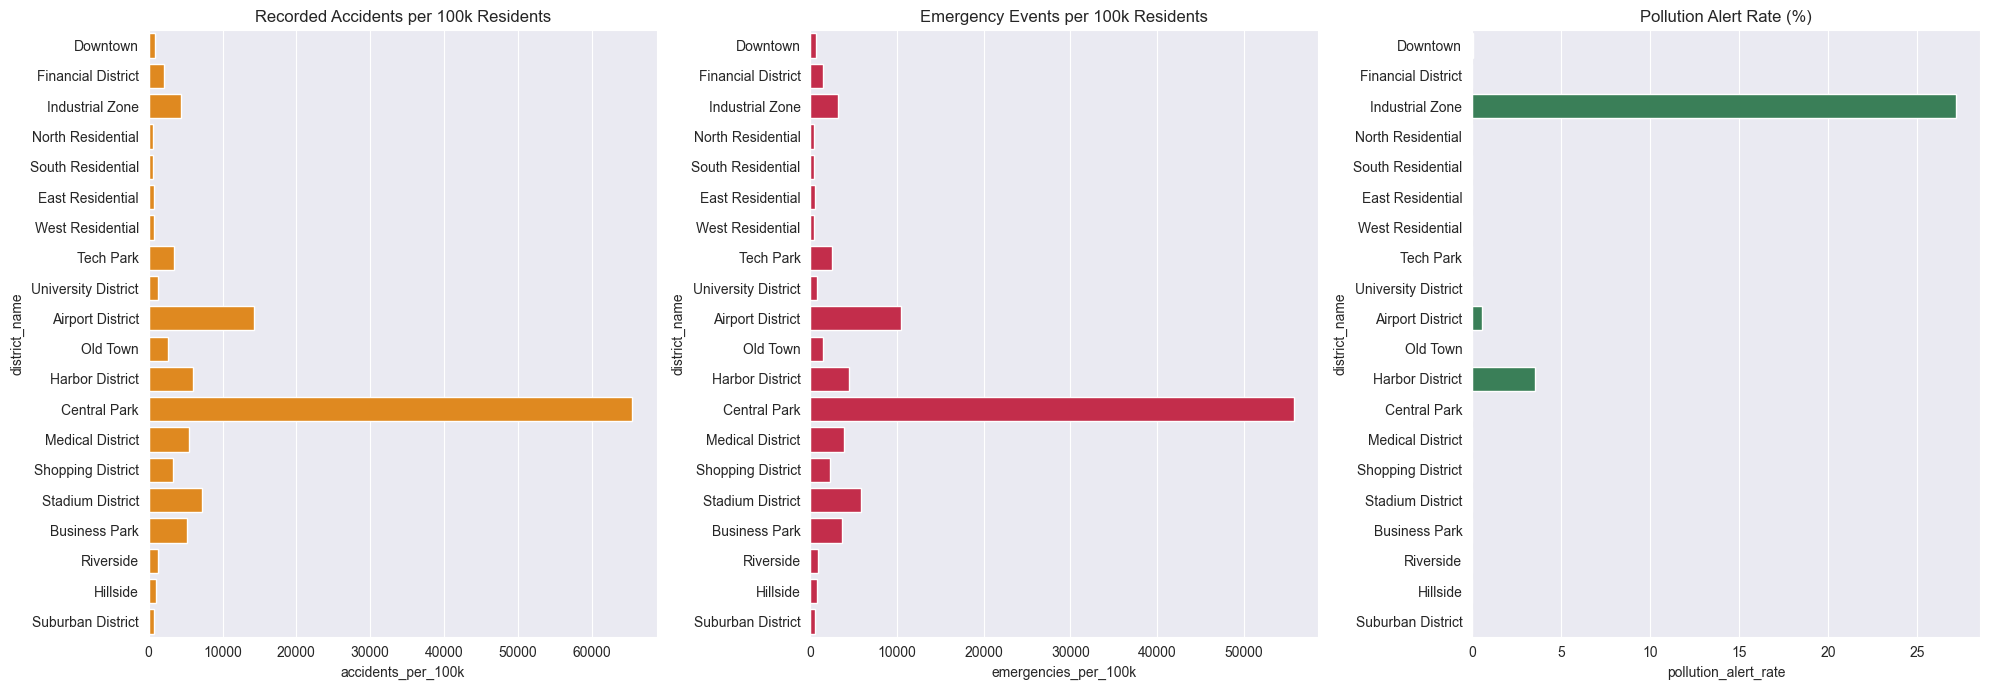

In [18]:
risk_profile['accidents_per_100k'] = traffic.groupby('district_id')['accident_count'].sum().values / risk_profile['population'] * 100000
risk_profile['emergencies_per_100k'] = risk_profile['emergency_count'] / risk_profile['population'] * 100000

fig, ax = plt.subplots(1, 3, figsize=(20, 7))
sns.barplot(risk_profile, x='accidents_per_100k', y='district_name', color='darkorange', ax=ax[0])
ax[0].set_title('Recorded Accidents per 100k Residents')
sns.barplot(risk_profile, x='emergencies_per_100k', y='district_name', color='crimson', ax=ax[1])
ax[1].set_title('Emergency Events per 100k Residents')
sns.barplot(risk_profile, x='pollution_alert_rate', y='district_name', color='seagreen', ax=ax[2])
ax[2].set_title('Pollution Alert Rate (%)')
plt.tight_layout()
plt.show()

## Sensor failures across all systems

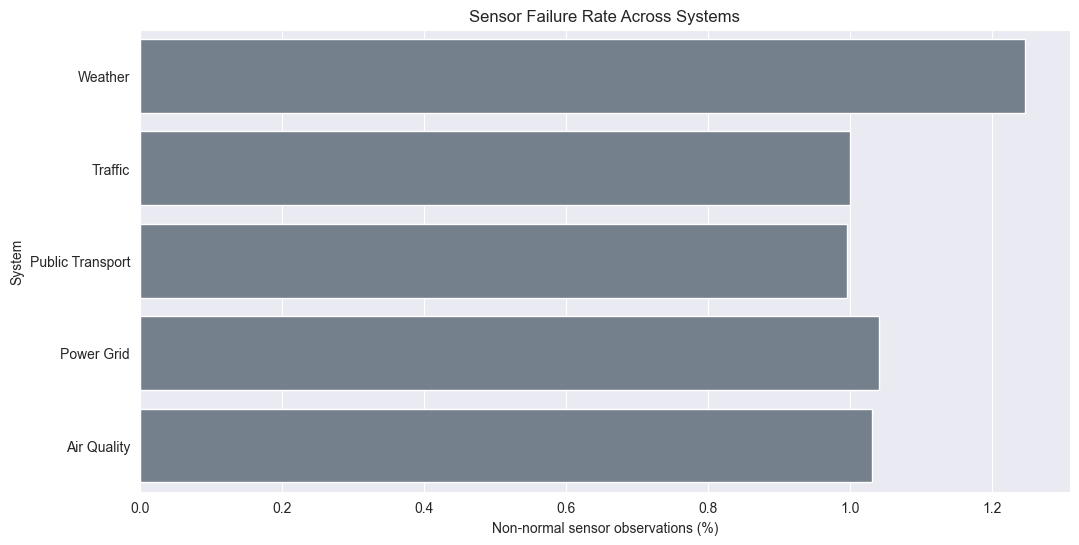

In [19]:
sensor_failures = pd.DataFrame({
    'system': ['Weather', 'Traffic', 'Public Transport', 'Power Grid', 'Air Quality'],
    'failure_rate': [
        (weather['sensor_status'] != 'Normal').mean() * 100,
        (traffic['sensor_status'] != 'Normal').mean() * 100,
        (transport['sensor_status'] != 'Normal').mean() * 100,
        (power['sensor_status'] != 'Normal').mean() * 100,
        (air['sensor_status'] != 'Normal').mean() * 100
    ]
})

sns.barplot(sensor_failures, x='failure_rate', y='system', color='slategray')
plt.title('Sensor Failure Rate Across Systems')
plt.xlabel('Non-normal sensor observations (%)')
plt.ylabel('System')
plt.show()